In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lthnhcng/ibmb-datasets/IMDB Dataset.csv


# 18. Experiment 1 — Attention distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Experiment 1 — Attention Distribution
# ============================================================

tokens = [
    "The",
    "movie",
    "was",
    "surprisingly",
    "good",
    "despite",
    "a",
    "very",
    "slow",
    "beginning"
]


# ------------------------------------------------------------
# Simulated token embeddings
# ------------------------------------------------------------

K = np.array([
    [0.10, 0.10, 0.10, 0.10],  # The
    [0.20, 0.20, 0.20, 0.20],  # movie
    [0.10, 0.20, 0.10, 0.20],  # was
    [0.70, 0.60, 0.50, 0.40],  # surprisingly
    [1.00, 0.90, 0.80, 0.70],  # good
    [0.20, 0.10, 0.20, 0.10],  # despite
    [0.10, 0.10, 0.20, 0.10],  # a
    [0.40, 0.30, 0.20, 0.30],  # very
    [-0.80, -0.70, -0.60, -0.50],  # slow
    [0.30, 0.20, 0.30, 0.20]   # beginning
])


# ------------------------------------------------------------
# Simulated sentiment query
# ------------------------------------------------------------

Q_sentiment = np.array([
    [1.0, 0.9, 0.8, 0.7]
])


# ------------------------------------------------------------
# Scaled Dot-Product Attention
# ------------------------------------------------------------

def softmax_stable(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)

    exp_x = np.exp(x - x_max)

    return exp_x / np.sum(
        exp_x,
        axis=axis,
        keepdims=True
    )


def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]

    scores = Q @ K.T
    scores = scores / np.sqrt(d_k)

    attention_weights = softmax_stable(
        scores,
        axis=-1
    )

    context = attention_weights @ V

    return scores, attention_weights, context


# ------------------------------------------------------------
# Run experiment
# ------------------------------------------------------------

scores, attention_weights, context = (
    scaled_dot_product_attention(
        Q_sentiment,
        K,
        K
    )
)


scores = scores[0]
attention_weights = attention_weights[0]


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 65)
print("EXPERIMENT 1 — ATTENTION DISTRIBUTION")
print("=" * 65)

print(
    f"{'Token':<15}"
    f"{'Score':>15}"
    f"{'Attention':>20}"
)

print("-" * 65)

for token, score, weight in zip(
    tokens,
    scores,
    attention_weights
):
    print(
        f"{token:<15}"
        f"{score:>15.4f}"
        f"{weight:>20.4f}"
    )

print("-" * 65)
print(f"Attention sum: {attention_weights.sum():.4f}")

EXPERIMENT 1 — ATTENTION DISTRIBUTION
Token                    Score           Attention
-----------------------------------------------------------------
The                     0.1700              0.0701
movie                   0.3400              0.0831
was                     0.2500              0.0759
surprisingly            0.9600              0.1545
good                    1.4700              0.2572
despite                 0.2600              0.0767
a                       0.2100              0.0730
very                    0.5200              0.0995
slow                   -1.1300              0.0191
beginning               0.4300              0.0909
-----------------------------------------------------------------
Attention sum: 1.0000


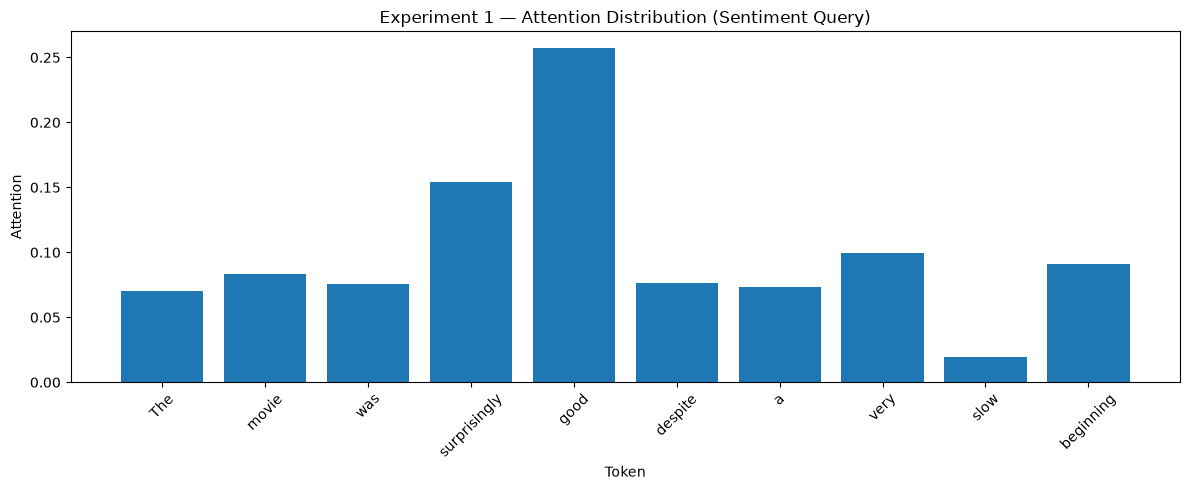

In [2]:
plt.figure(figsize=(12, 5))

plt.bar(tokens, attention_weights)

plt.xlabel("Token")
plt.ylabel("Attention")
plt.title(
    "Experiment 1 — Attention Distribution "
    "(Sentiment Query)"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 19. Experiment 2 — Query thay đổi

In [3]:
# ============================================================
# Experiment 2 — Query thay đổi
# ============================================================

Q_sentiment = np.array([
    [1.0, 0.9, 0.8, 0.7]
])


Q_topic = np.array([
    [0.2, 0.4, 0.8, 1.0]
])


# ------------------------------------------------------------
# Sentiment query
# ------------------------------------------------------------

scores_sentiment, attention_sentiment, _ = (
    scaled_dot_product_attention(
        Q_sentiment,
        K,
        K
    )
)


# ------------------------------------------------------------
# Topic query
# ------------------------------------------------------------

scores_topic, attention_topic, _ = (
    scaled_dot_product_attention(
        Q_topic,
        K,
        K
    )
)


scores_sentiment = scores_sentiment[0]
attention_sentiment = attention_sentiment[0]

scores_topic = scores_topic[0]
attention_topic = attention_topic[0]


# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

print("=" * 85)
print("EXPERIMENT 2 — QUERY THAY ĐỔI")
print("=" * 85)

print(
    f"{'Token':<15}"
    f"{'Sent. Score':>15}"
    f"{'Sent. Attn':>15}"
    f"{'Topic Score':>15}"
    f"{'Topic Attn':>15}"
)

print("-" * 85)

for i, token in enumerate(tokens):

    print(
        f"{token:<15}"
        f"{scores_sentiment[i]:>15.4f}"
        f"{attention_sentiment[i]:>15.4f}"
        f"{scores_topic[i]:>15.4f}"
        f"{attention_topic[i]:>15.4f}"
    )

EXPERIMENT 2 — QUERY THAY ĐỔI
Token              Sent. Score     Sent. Attn    Topic Score     Topic Attn
-------------------------------------------------------------------------------------
The                     0.1700         0.0701         0.1200         0.0831
movie                   0.3400         0.0831         0.2400         0.0936
was                     0.2500         0.0759         0.1900         0.0891
surprisingly            0.9600         0.1545         0.5900         0.1329
good                    1.4700         0.2572         0.9500         0.1905
despite                 0.2600         0.0767         0.1700         0.0873
a                       0.2100         0.0730         0.1600         0.0864
very                    0.5200         0.0995         0.3300         0.1025
slow                   -1.1300         0.0191        -0.7100         0.0362
beginning               0.4300         0.0909         0.2900         0.0984


# 23. Experiment 3 — Attention visualization

In [4]:
import numpy as np
import matplotlib.pyplot as plt


sentence_1 = [
    "The",
    "cat",
    "that",
    "I",
    "adopted",
    "yesterday",
    "is",
    "sleeping"
]


sentence_2 = [
    "The",
    "book",
    "that",
    "I",
    "bought",
    "yesterday",
    "was",
    "expensive"
]

In [ ]:
# create embeding giả lập
embedding_dim = 8


np.random.seed(42)


embeddings = {
    "The": np.random.randn(embedding_dim),
    "cat": np.random.randn(embedding_dim),
    "that": np.random.randn(embedding_dim),
    "I": np.random.randn(embedding_dim),
    "adopted": np.random.randn(embedding_dim),
    "yesterday": np.random.randn(embedding_dim),
    "is": np.random.randn(embedding_dim),
    "sleeping": np.random.randn(embedding_dim),

    "book": np.random.randn(embedding_dim),
    "bought": np.random.randn(embedding_dim),
    "was": np.random.randn(embedding_dim),
    "expensive": np.random.randn(embedding_dim),
}

In [6]:
def create_embedding_matrix(tokens):
    return np.array([
        embeddings[token]
        for token in tokens
    ])

In [7]:
def softmax_stable(x, axis=-1):
    x_max = np.max(
        x,
        axis=axis,
        keepdims=True
    )

    exp_x = np.exp(x - x_max)

    return exp_x / np.sum(
        exp_x,
        axis=axis,
        keepdims=True
    )


def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]

    scores = Q @ K.T

    scores = scores / np.sqrt(d_k)

    attention_weights = softmax_stable(
        scores,
        axis=-1
    )

    context = attention_weights @ V

    return scores, attention_weights, context

In [8]:
X1 = create_embedding_matrix(sentence_1)


scores_1, attention_1, context_1 = (
    scaled_dot_product_attention(
        X1,
        X1,
        X1
    )
)


print("Attention matrix:")
print(attention_1)

Attention matrix:
[[0.5967479  0.01575543 0.01329237 0.07213636 0.02546808 0.07706667
  0.15562865 0.04390452]
 [0.00720754 0.50855286 0.09446017 0.04475965 0.22101692 0.04598634
  0.00574202 0.0722745 ]
 [0.00803252 0.12477895 0.72615235 0.01729604 0.0581658  0.01087599
  0.01376164 0.04093671]
 [0.06297932 0.08542277 0.02498854 0.48817373 0.06022276 0.16645963
  0.06786415 0.0438891 ]
 [0.00994121 0.18858689 0.03757172 0.02692525 0.62139004 0.05286761
  0.02669917 0.03601812]
 [0.07545441 0.0984215  0.01762128 0.18667372 0.13260651 0.34563425
  0.09636912 0.04721922]
 [0.14489871 0.01168645 0.02120293 0.07237217 0.06368393 0.09164206
  0.56448251 0.03003124]
 [0.05139665 0.18494978 0.07930289 0.05884892 0.1080199  0.05645812
  0.03775929 0.42326444]]


In [9]:
print(attention_1.shape)

(8, 8)


## Visualize attention matrix

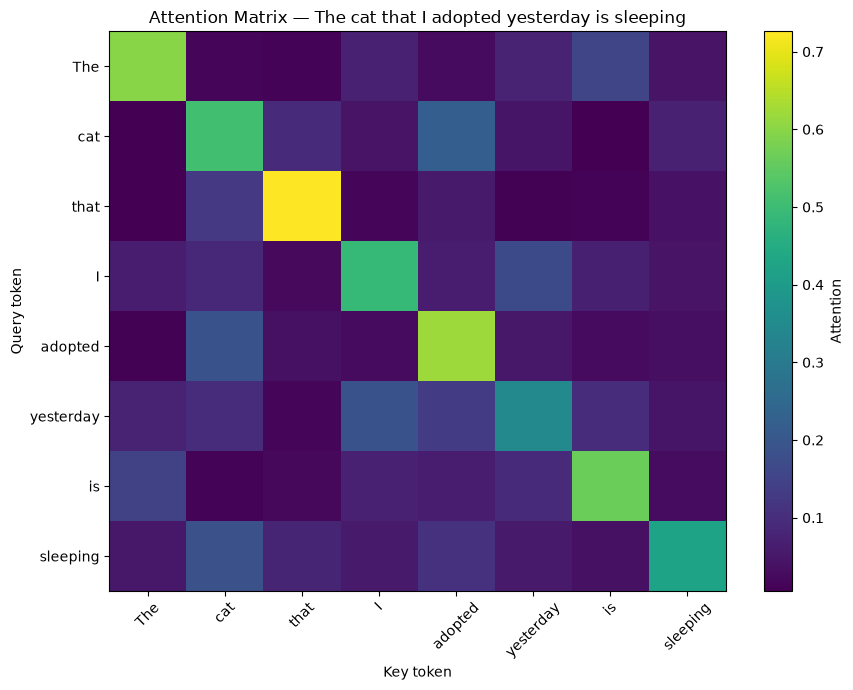

In [21]:
plt.figure(figsize=(9, 7))

plt.imshow(
    attention_1,
    aspect="auto"
)

plt.colorbar(
    label="Attention"
)

plt.xticks(
    range(len(sentence_1)),
    sentence_1,
    rotation=45
)

plt.yticks(
    range(len(sentence_1)),
    sentence_1
)

plt.xlabel("Key token")
plt.ylabel("Query token")

plt.title(
    "Attention Matrix — "
    "The cat that I adopted yesterday is sleeping"
)

plt.tight_layout()
plt.savefig("confusion_matrix_1")
plt.show()

In [11]:
X2 = create_embedding_matrix(sentence_2)


scores_2, attention_2, context_2 = (
    scaled_dot_product_attention(
        X2,
        X2,
        X2
    )
)

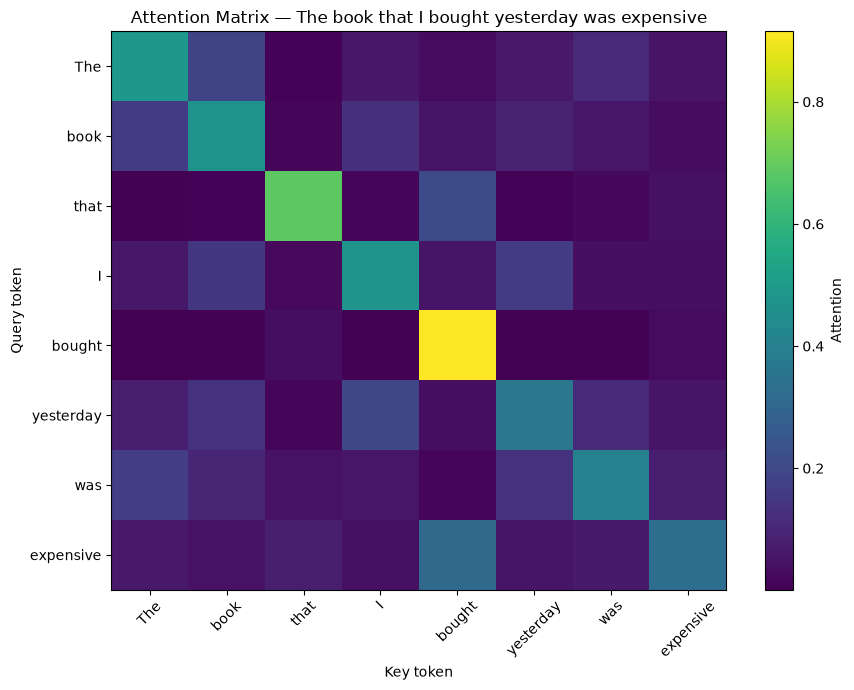

In [20]:
plt.figure(figsize=(9, 7))

plt.imshow(
    attention_2,
    aspect="auto"
)

plt.colorbar(
    label="Attention"
)

plt.xticks(
    range(len(sentence_2)),
    sentence_2,
    rotation=45
)

plt.yticks(
    range(len(sentence_2)),
    sentence_2
)

plt.xlabel("Key token")
plt.ylabel("Query token")

plt.title(
    "Attention Matrix — "
    "The book that I bought yesterday was expensive"
)

plt.tight_layout()
plt.savefig("confusion_matrix_2")
plt.show()

In [13]:
def show_token_attention(
    token,
    tokens,
    attention_matrix
):
    index = tokens.index(token)

    weights = attention_matrix[index]

    print(f"\nQuery token: {token}")
    print("-" * 45)

    ranking = sorted(
        zip(tokens, weights),
        key=lambda x: x[1],
        reverse=True
    )

    for target_token, weight in ranking:
        print(
            f"{target_token:<15}"
            f"{weight:.4f}"
        )

In [14]:
show_token_attention(
    "cat",
    sentence_1,
    attention_1
)


Query token: cat
---------------------------------------------
cat            0.5086
adopted        0.2210
that           0.0945
sleeping       0.0723
yesterday      0.0460
I              0.0448
The            0.0072
is             0.0057


In [15]:
show_token_attention(
    "adopted",
    sentence_1,
    attention_1
)


Query token: adopted
---------------------------------------------
adopted        0.6214
cat            0.1886
yesterday      0.0529
that           0.0376
sleeping       0.0360
I              0.0269
is             0.0267
The            0.0099


In [16]:
show_token_attention(
    "sleeping",
    sentence_1,
    attention_1
)


Query token: sleeping
---------------------------------------------
sleeping       0.4233
cat            0.1849
adopted        0.1080
that           0.0793
I              0.0588
yesterday      0.0565
The            0.0514
is             0.0378


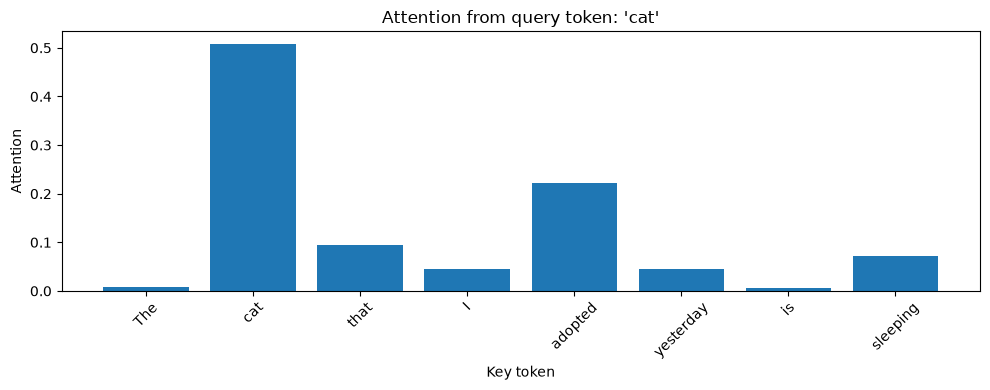

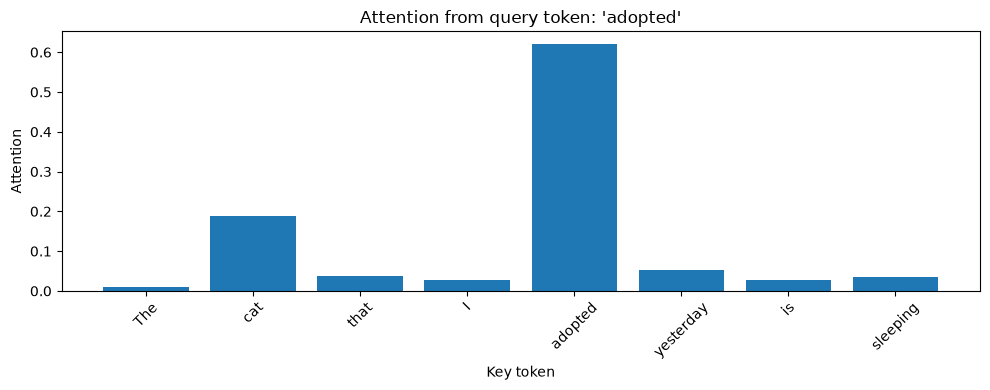

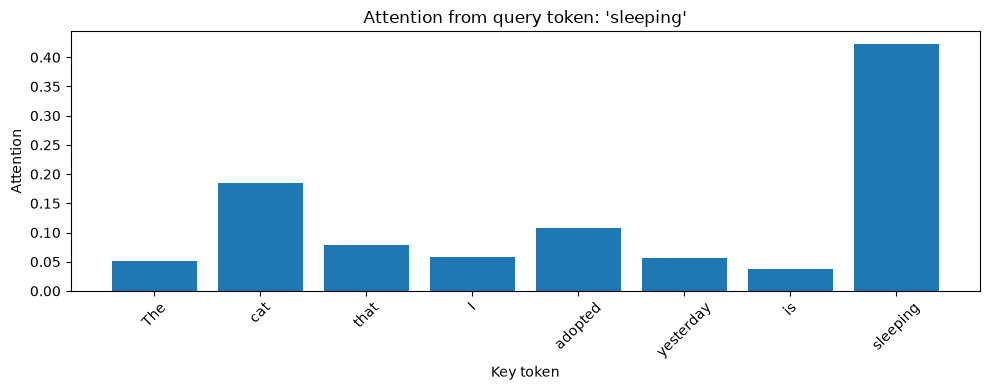

In [17]:
selected_tokens = [
    "cat",
    "adopted",
    "sleeping"
]


for token in selected_tokens:

    index = sentence_1.index(token)

    weights = attention_1[index]

    plt.figure(figsize=(10, 4))

    plt.bar(
        sentence_1,
        weights
    )

    plt.xlabel("Key token")
    plt.ylabel("Attention")

    plt.title(
        f"Attention from query token: '{token}'"
    )

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

In [18]:
selected_tokens = [
    "cat",
    "adopted",
    "sleeping"
]


print(
    f"{'Query':<15}"
    f"{'Most attended tokens':<40}"
)

print("-" * 55)


for token in selected_tokens:

    index = sentence_1.index(token)

    weights = attention_1[index]

    ranking = sorted(
        zip(sentence_1, weights),
        key=lambda x: x[1],
        reverse=True
    )

    top_tokens = ranking[:3]

    description = ", ".join(
        f"{t} ({w:.3f})"
        for t, w in top_tokens
    )

    print(
        f"{token:<15}"
        f"{description:<40}"
    )

Query          Most attended tokens                    
-------------------------------------------------------
cat            cat (0.509), adopted (0.221), that (0.094)
adopted        adopted (0.621), cat (0.189), yesterday (0.053)
sleeping       sleeping (0.423), cat (0.185), adopted (0.108)


## Nhận xét Experiment 3
- Attention matrix cho thấy attention được phân phối khác nhau giữa các cặp token trong sequence. Mỗi hàng của ma trận tương ứng với một query token, trong khi mỗi cột tương ứng với một key token. Giá trị tại mỗi ô biểu diễn mức độ attention mà query token phân phối tới key token tương ứng.

- Đối với câu: "The cat I adopted yesterday is sleeping". Ta quan sát attention distribution của ba token cat, adopted và sleeping. Với mỗi token, các attention weights cho biết token đó đang tập trung nhiều hơn vào token nào trong sequence.

- Kết quả cho thấy attention pattern có thể thay đổi giữa các token khác nhau. Tuy nhiên attenrion visualization chỉ cung cấp bằng chứng trực tiếp về phân phối attention của mô hình. Không nên tự động diễn giải một attention pattern cụ thể thành bằng chứng mô hình đã hiểu một quan hệ ngữ pháp hoặc ngữ nghĩa cụ thể.

- Một heatmap có thể cho thấy 2 token có attention cao tới nhau, nhưng điều đó không đủ để khẳng định mô hình đang thực hiện một dạng reasoning hoặc thực sự hiểu quan hệ ngôn ngữ giữa hai token

- Vì vậy, attention visualization trong thí nghiệm này được sử dụng chủ yếu để quan sát attention được phân phối trên sequence, thay vì dùng nó như bằng chứng trực tiếp về khả năng hiểu ngôn ngữ của mô hình

# 24. Experiment 4 — RNN context vs Attention context

In [5]:
import os, re, time, random, glob
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device {device}")

Device cuda


In [6]:
## load dataset
csv_path = "/kaggle/input/datasets/lthnhcng/ibmb-datasets/IMDB Dataset.csv"

df = pd.read_csv(csv_path)
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [7]:
TEXT_COL = "review"
LABEL_COL = "sentiment"

df["label"] = df[LABEL_COL].astype(str).str.lower().isin(["positive", "pos", "1"]).astype(int)
print(df["label"].value_counts())
df.head()

label
1    25000
0    25000
Name: count, dtype: int64


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


In [12]:
# preprocessing: tokenize, vocab, padding, split
MAX_LEN = 256
VOCAB_SIZE = 20000
BATCH_SIZE = 64

def tokenize(t):
    t = re.sub(r"<.*?>", " ", t.lower())
    return re.findall(r"[a-z0-9']+|[!?]", t)

df["tokens"] = df[TEXT_COL].astype(str).apply(tokenize)

train_df, tmp_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=SEED
)

val_df, test_df = train_test_split(
    tmp_df, test_size=0.5, stratify=tmp_df["label"], random_state=SEED
)

print(len(train_df), len(val_df), len(test_df))

# vocab chi build tu train
counter = Counter(w for toks in train_df["tokens"] for w in toks)
itos = ["<pad>, <unk>"] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}

def encode(split):
    X = np.zeros((len(split), MAX_LEN), dtype=np.int64)
    L = np.zeros(len(split), dtype=np.int64)
    for i, toks in enumerate(split["tokens"]):
        ids = [stoi.get(w, 1) for w in toks[:MAX_LEN]]
        L[i] = max(len(ids), 1)
        X[i, :len(ids)] = ids

    return torch.tensor(X), torch.tensor(L), torch.tensor(split["label"].values)

def make_loader(split, shuffle):
    X, L, y = encode(split)
    return DataLoader(TensorDataset(X, L, y), batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(train_df, True)
val_loader = make_loader(val_df, False)
test_loader = make_loader(test_df, False)

print("Vocab size: ", len(itos))

40000 5000 5000
Vocab size:  19999


In [20]:
# 2 model
# lstm: embedding -> lstm -> final hidden state -> classifier
# attention: embedding + (positional embedding) -> selft attention -> context representation -> classifier

EMB_DIM = 128
HID_DIM = 128
DROPOUT = 0.3

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB_DIM, padding_idx=0)
        self.lstm = nn.LSTM(EMB_DIM, HID_DIM, batch_first=True)
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HID_DIM, 2)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        return self.fc(self.drop(h[-1]))


class SelfAttentionClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB_DIM, padding_idx=0)
        self.pos = nn.Embedding(MAX_LEN, EMB_DIM)
        self.Wq, self.Wk, self.Wv = (nn.Linear(EMB_DIM, HID_DIM) for _ in range(3))
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HID_DIM, 2)

    def forward(self, x, lengths, return_attn=False):
        B, T = x.shape
        pad_mask = (x == 0)
        e = self.emb(x) + self.pos(torch.arange(T, device=x.device))
        e = self.drop(e)
        q, k, v = self.Wq(e), self.Wk(e), self.Wv(e)
        scores = q @ k.transpose(1, 2) / (HID_DIM ** 0.5)
        scores = scores.masked_fill(pad_mask[:, None, :], float("-inf"))
        attn = torch.softmax(scores, dim=-1)
        ctx = attn @ v
        keep = (~pad_mask).unsqueeze(-1).float()
        pooled = (ctx * keep).sum(1) / keep.sum(1).clamp(min=1)
        logits = self.fc(self.drop(pooled))

        return (logits, attn) if return_attn else logits

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("LSTM params     :", count_params(LSTMClassifier(len(itos))))
print("Attention params:", count_params(SelfAttentionClassifier(len(itos))))

LSTM params     : 2692226
Attention params: 2642434


In [42]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(model, loader, name):
    model.eval()
    preds, gold = [], []

    with torch.no_grad():
        for x, l, y in loader:
            out = model(x.to(device), l.to(device))
            preds += out.argmax(-1).cpu().tolist()
            gold += y.tolist()

    cm = confusion_matrix(gold, preds)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{name}.png')
    plt.show()

In [30]:
# train / evaluate
EPOCHS = 5
LR = 1e-3

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, gold = [], []
    for x, l, y in loader:
        out = model(x.to(device), l.to(device))
        preds += out.argmax(-1).cpu().tolist()
        gold  += y.tolist()
    return accuracy_score(gold, preds), f1_score(gold, preds)

def fit(model, name):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best_val, best_state, total_time = 0, None, 0.0
    for ep in range(1, EPOCHS + 1):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        loss_sum = 0
        for x, l, y in train_loader:
            x, l, y = x.to(device), l.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x, l), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            loss_sum += loss.item()
        if device.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0
        total_time += dt
        va, vf = evaluate(model, val_loader)
        print(f"[{name}] epoch {ep}  loss={loss_sum/len(train_loader):.4f}  val_acc={va:.4f}  val_f1={vf:.4f}  ({dt:.1f}s)")
        if va > best_val:
            best_val = va
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    acc, f1 = evaluate(model, test_loader)
    return dict(Model=name, Accuracy=round(acc, 4), F1=round(f1, 4),
                **{"Training time (s)": round(total_time, 1)}, Parameters=count_params(model))

In [22]:
torch.manual_seed(SEED)
lstm_model = LSTMClassifier(len(itos))
res_lstm = fit(lstm_model, "LSTM")

torch.manual_seed(SEED)
attn_model = SelfAttentionClassifier(len(itos))
res_attn = fit(attn_model, "Attention")

results = pd.DataFrame([res_lstm, res_attn])
results

[LSTM] epoch 1  loss=0.6171  val_acc=0.7092  val_f1=0.7360  (9.2s)
[LSTM] epoch 2  loss=0.4781  val_acc=0.8236  val_f1=0.8201  (9.2s)
[LSTM] epoch 3  loss=0.3885  val_acc=0.8138  val_f1=0.8233  (9.2s)
[LSTM] epoch 4  loss=0.3262  val_acc=0.8708  val_f1=0.8713  (9.0s)
[LSTM] epoch 5  loss=0.2816  val_acc=0.8770  val_f1=0.8777  (9.0s)
[Attention] epoch 1  loss=0.5051  val_acc=0.8368  val_f1=0.8446  (4.9s)
[Attention] epoch 2  loss=0.3636  val_acc=0.8664  val_f1=0.8708  (4.8s)
[Attention] epoch 3  loss=0.3112  val_acc=0.8734  val_f1=0.8776  (4.9s)
[Attention] epoch 4  loss=0.2790  val_acc=0.8810  val_f1=0.8814  (4.9s)
[Attention] epoch 5  loss=0.2565  val_acc=0.8824  val_f1=0.8854  (4.9s)


,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.8784,0.8773,45.7,2692226
1,Attention,0.8854,0.8872,24.4,2642434


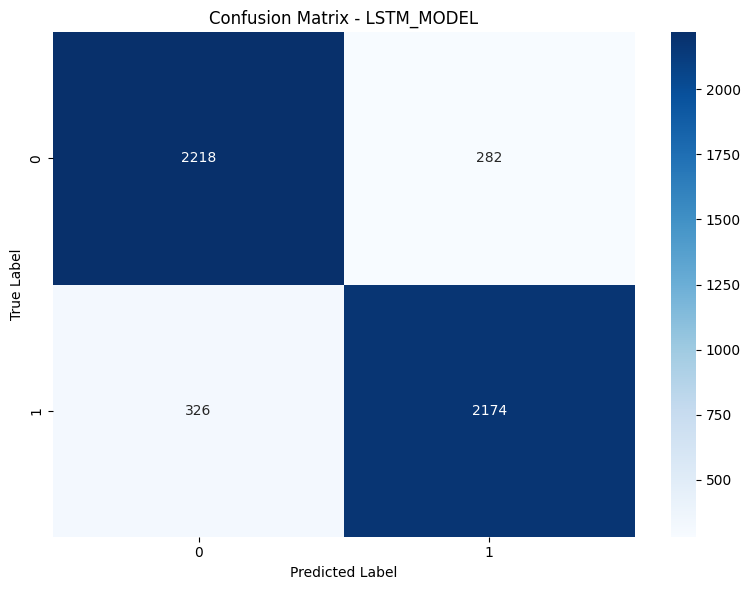

In [45]:
plot_confusion_matrix(lstm_model, test_loader, 'LSTM_MODEL')

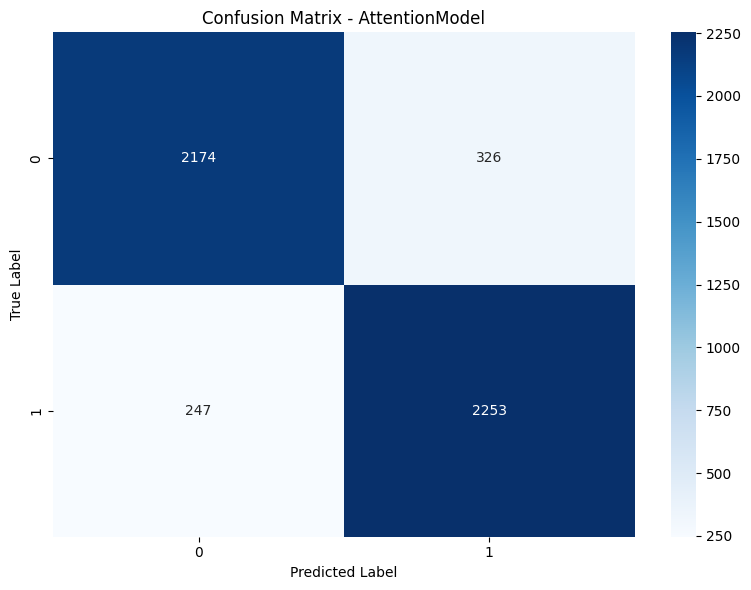

In [46]:
plot_confusion_matrix(attn_model, test_loader, 'AttentionModel')

Prediction: negative
Top tokens được chú ý: [('boring', 0.171), ('was', 0.161), ('wonderful', 0.119), ('great', 0.11), ('absolutely', 0.075), ('acting', 0.056), ('little', 0.053), ('was', 0.049)]


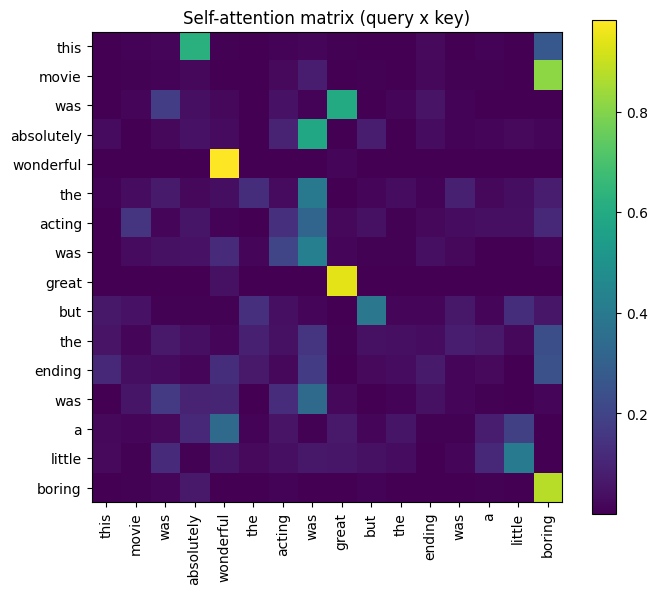

In [23]:
# representation khacs nhau
def show_attention(text, top_k=8):
    toks = tokenize(text)[:MAX_LEN]
    ids = [stoi.get(w, 1) for w in toks]
    x = torch.tensor([ids + [0] * (MAX_LEN - len(ids))]).to(device)
    l = torch.tensor([len(ids)]).to(device)
    attn_model.eval()
    with torch.no_grad():
        logits, attn = attn_model(x, l, return_attn=True)
    n = len(ids)
    received = attn[0, :n, :n].mean(0).cpu().numpy()      # mỗi token được chú ý bao nhiêu
    order = received.argsort()[::-1][:top_k]
    pred = "positive" if logits.argmax(-1).item() == 1 else "negative"
    print("Prediction:", pred)
    print("Top tokens được chú ý:", [(toks[i], round(float(received[i]), 3)) for i in order])
    return attn[0, :n, :n].cpu().numpy(), toks

A, toks = show_attention("This movie was absolutely wonderful, the acting was great but the ending was a little boring")

n = min(len(toks), 20)
plt.figure(figsize=(7, 6))
plt.imshow(A[:n, :n], cmap="viridis")
plt.xticks(range(n), toks[:n], rotation=90); plt.yticks(range(n), toks[:n])
plt.title("Self-attention matrix (query x key)"); plt.colorbar(); plt.tight_layout(); plt.show()

## Representaion khác nhau
- **LSTM**: đọc tuần tự từng token, nén toàn bộ câu vào **một vector final hidden state**. Thông tin đầu câu phải đi qua nhiều bước nên dễ bị mất dần, và không thể tính song song theo thời gian.
- **Self-Attention**: mỗi token **nhìn trực tiếp tất cả token khác** (ma trận T×T), tạo biểu diễn theo ngữ cảnh cho từng vị trí, rồi mới gộp (pooling) thành context vector. Khoảng cách giữa hai token luôn là 1 bước, tính song song được, và ta có thể quan sát được attention weights.
- Đổi lại, attention không có sẵn thông tin thứ tự (phải thêm positional embedding) và tốn bộ nhớ/tính toán theo T² (Experiment 5).
- Trong thực nghiệm này, Self-Attention đạt hiệu năng phân loại tốt hơn và huấn luyện nhanh hơn LSTM với số lượng tham số tương đương. Kết quả minh họa lợi ích của khả năng tương tác trực tiếp giữa các token và khả năng tính toán song song của Self-Attention.

# 25. Experiment 5 — Sequence length và computational cost

In [24]:
lengths = [10, 100, 500, 1000]
rows = []
for T in lengths:
    n = T * T
    rows.append({
        "Sequence length": T,
        "Attention matrix": f"({T}x{T})",
        "Số phần tử": n,
        "Bộ nhớ 1 head, 1 câu (MB, float32)": round(n * 4 / 1024**2, 3),
        "Batch 32 x 8 heads (MB)": round(n * 4 * 32 * 8 / 1024**2, 1),
    })
pd.DataFrame(rows)

,Sequence length,Attention matrix,Số phần tử,"Bộ nhớ 1 head, 1 câu (MB, float32)",Batch 32 x 8 heads (MB)
0,10,(10x10),100,0.000,0.1
1,100,(100x100),10000,0.038,9.8
2,500,(500x500),250000,0.954,244.1
3,1000,(1000x1000),1000000,3.815,976.6


,T,Số phần tử (T²),Thời gian (ms),Peak GPU mem (MB)
0,10,100,0.376,119.0
1,100,10000,0.126,120.6
2,500,250000,0.552,146.8
3,1000,1000000,1.625,218.8
4,2000,4000000,6.226,500.9
5,4000,16000000,24.361,1615.5


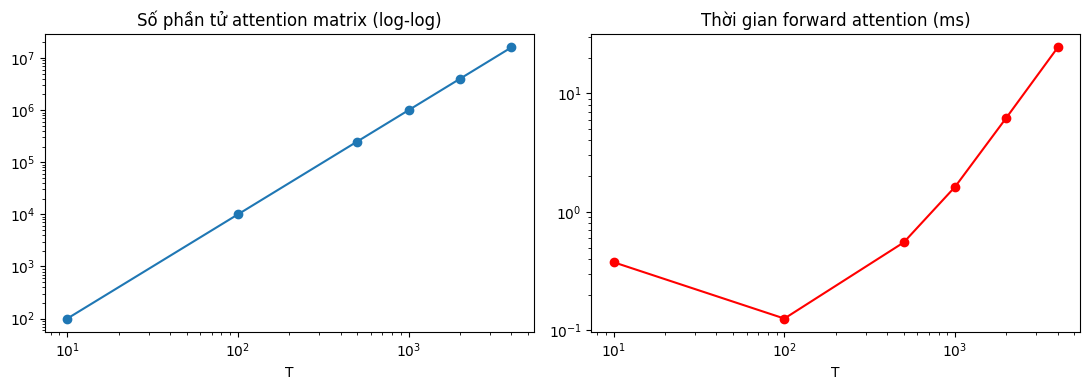

In [25]:
# do thoi gian va bo nho cua phep attention (Qk^T -> softmax -> V)
def bench(T, d=64, batch=8, reps=5):
    q = torch.randn(batch, T, d, device=device)
    k = torch.randn(batch, T, d, device=device)
    v = torch.randn(batch, T, d, device=device)
    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        a = torch.softmax(q @ k.transpose(1, 2) / d ** 0.5, dim=-1)
        out = a @ v
    if device.type == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / reps * 1000
    mem = torch.cuda.max_memory_allocated() / 1024**2 if device.type == "cuda" else float("nan")
    return ms, mem

bench_rows = []
for T in [10, 100, 500, 1000, 2000, 4000]:
    try:
        ms, mem = bench(T)
        bench_rows.append({"T": T, "Số phần tử (T²)": T * T, "Thời gian (ms)": round(ms, 3), "Peak GPU mem (MB)": round(mem, 1)})
    except RuntimeError as e:
        bench_rows.append({"T": T, "Số phần tử (T²)": T * T, "Thời gian (ms)": "OOM", "Peak GPU mem (MB)": "OOM"})
        torch.cuda.empty_cache()
bench_df = pd.DataFrame(bench_rows)
display(bench_df)

ok = bench_df[bench_df["Thời gian (ms)"] != "OOM"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(ok["T"], ok["Số phần tử (T²)"], "o-"); ax[0].set_title("Số phần tử attention matrix (log-log)"); ax[0].set_xlabel("T")
ax[1].loglog(ok["T"], ok["Thời gian (ms)"].astype(float), "o-r"); ax[1].set_title("Thời gian forward attention (ms)"); ax[1].set_xlabel("T")
plt.tight_layout(); plt.show()

## Trả lời: tại sao self-attention tốn chi phí khi sequence rất dài?
- Ma trận attention là T × T, nên số phần tử là **T²**: T tăng 10 lần thì số phần tử tăng **100 lần** (100 → 10 000, 1000 → 1 000 000).
- **Bộ nhớ**: phải lưu ma trận này (cho mỗi head, mỗi câu, mỗi layer) để backward, nên bộ nhớ tăng O(T²) và dễ OOM khi T lớn hoặc batch/số head lớn.
- **Tính toán**: QKᵀ và softmax(·)V đều cần O(T²·d) phép nhân, trong khi RNN/LSTM chỉ O(T·d²) (nhưng tuần tự).
- Vì vậy văn bản dài (tài liệu, sách, code) khó xử lý trực tiếp; cần cắt đoạn (truncate/chunk) hoặc dùng các biến thể hiệu quả (sparse/local attention, linear attention, FlashAttention...).

# 26. Application — Context-aware sentiment

In [32]:
EPOCHS, LR = 5, 1e-3
CKPT = "/kaggle/working/attn_model.pt"

torch.manual_seed(SEED)
model = SelfAttentionClassifier(len(itos)).to(device)

if os.path.exists(CKPT):
    model.load_state_dict(torch.load(CKPT, map_location=device))
    print("Loaded checkpoint", CKPT)
else:
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best_val, best_state = 0, None
    for ep in range(1, EPOCHS + 1):
        model.train(); loss_sum = 0
        for x, l, y in train_loader:
            x, l, y = x.to(device), l.to(device), y.to(device)

            opt.zero_grad()
            loss = F.cross_entropy(model(x, l), y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); loss_sum += loss.item()
        va, vf = evaluate(model, val_loader)
        print(f"epoch {ep}  loss={loss_sum/len(train_loader):.4f}  val_acc={va:.4f}  val_f1={vf:.4f}")
        if va > best_val:
            best_val = va; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    os.makedirs(os.path.dirname(CKPT), exist_ok=True)
    torch.save(model.state_dict(), CKPT)

acc, f1 = evaluate(model, test_loader)
print(f"TEST  accuracy={acc:.4f}  F1={f1:.4f}")

epoch 1  loss=0.5051  val_acc=0.8368  val_f1=0.8446
epoch 2  loss=0.3636  val_acc=0.8664  val_f1=0.8708
epoch 3  loss=0.3112  val_acc=0.8734  val_f1=0.8776
epoch 4  loss=0.2790  val_acc=0.8810  val_f1=0.8814
epoch 5  loss=0.2565  val_acc=0.8824  val_f1=0.8854
TEST  accuracy=0.8854  F1=0.8872


In [38]:
LABELS = ["negative", "positive"]

def text_to_ids(text):
    toks = tokenize(text)[:MAX_LEN]
    return toks, [stoi.get(w, 1) for w in toks]

def pad_batch(id_lists):
    X = np.zeros((len(id_lists), MAX_LEN), dtype=np.int64)
    lengths = []

    for i, ids in enumerate(id_lists):
        X[i, :len(ids)] = ids
        lengths.append(len(ids))

    return (
        torch.tensor(X).to(device),
        torch.tensor(lengths, dtype=torch.long).to(device)
    )

@torch.no_grad()
def probs_from_ids(id_lists, chunk=128):
    """Xác suất [neg, pos] cho nhiều chuỗi id (dùng cho occlusion)."""
    model.eval(); out = []
    x, lengths = pad_batch(id_lists[s:s+chunk])
    for s in range(0, len(id_lists), chunk):
        out.append(torch.softmax(model(x, lengths), -1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def analyze(text):
    toks, ids = text_to_ids(text)
    model.eval()
    x, lengths = pad_batch([ids])

    logits, attn = model(
        x,
        lengths,
        return_attn=True
    )
    p = torch.softmax(logits, -1)[0].cpu().numpy()
    n = len(ids)
    A = attn[0, :n, :n].cpu().numpy()                 # (n, n) query x key
    return dict(toks=toks, ids=ids, probs=p, pred=int(p.argmax()), A=A, received=A.mean(0))

def plot_attention(r, title=None, max_tok=30):
    toks, A, rec = r["toks"][:max_tok], r["A"][:max_tok, :max_tok], r["received"][:max_tok]
    n = len(toks)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
    im = ax[0].imshow(A, cmap="viridis")
    ax[0].set_xticks(range(n)); ax[0].set_xticklabels(toks, rotation=90)
    ax[0].set_yticks(range(n)); ax[0].set_yticklabels(toks)
    ax[0].set_xlabel("key (token được nhìn)"); ax[0].set_ylabel("query (token đang nhìn)")
    ax[0].set_title("Ma trận self-attention"); fig.colorbar(im, ax=ax[0], fraction=0.046)
    ax[1].bar(range(n), rec, color="tab:orange")
    ax[1].set_xticks(range(n)); ax[1].set_xticklabels(toks, rotation=90)
    ax[1].set_title("Attention received = trọng số mỗi token trong context vector")
    pred = LABELS[r["pred"]]
    fig.suptitle(f"{title or ''}  →  {pred} (p_pos = {r['probs'][1]:.3f})", fontsize=12)
    plt.tight_layout(); plt.show()

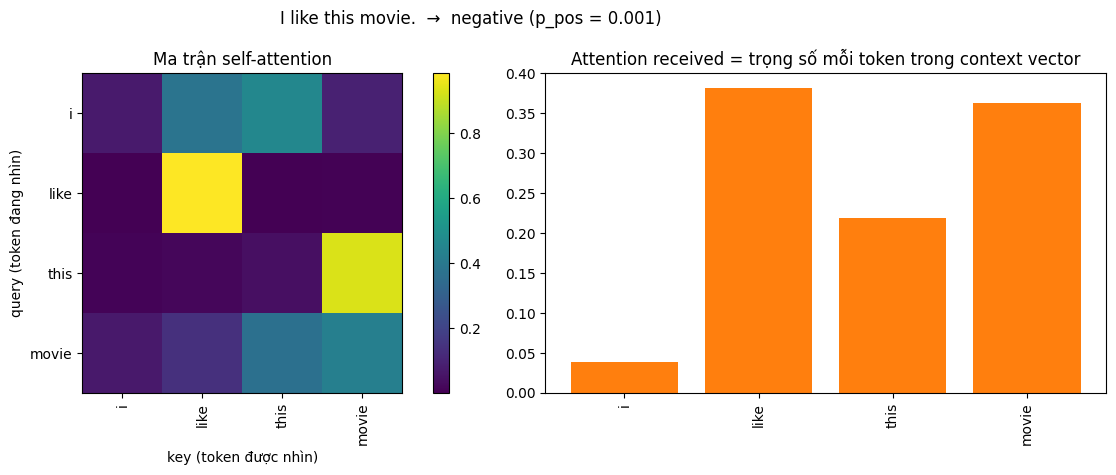

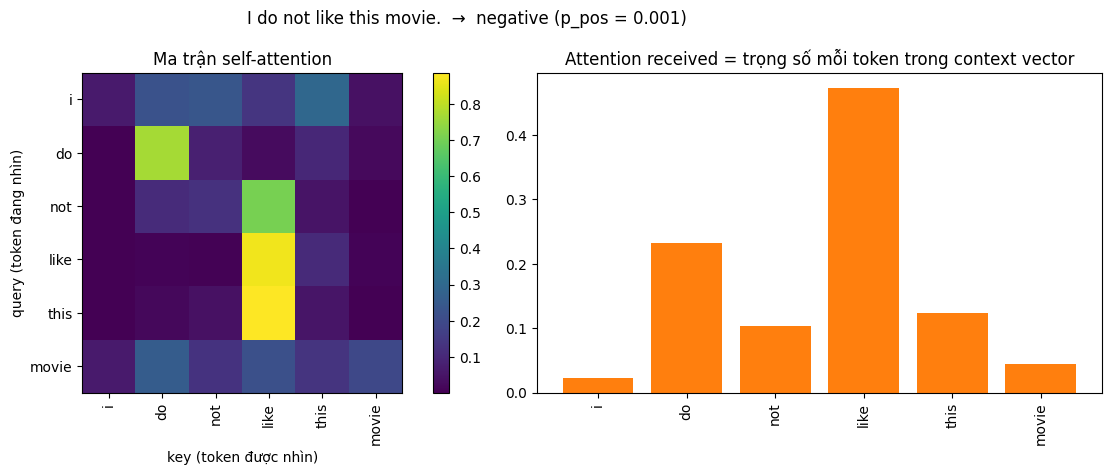

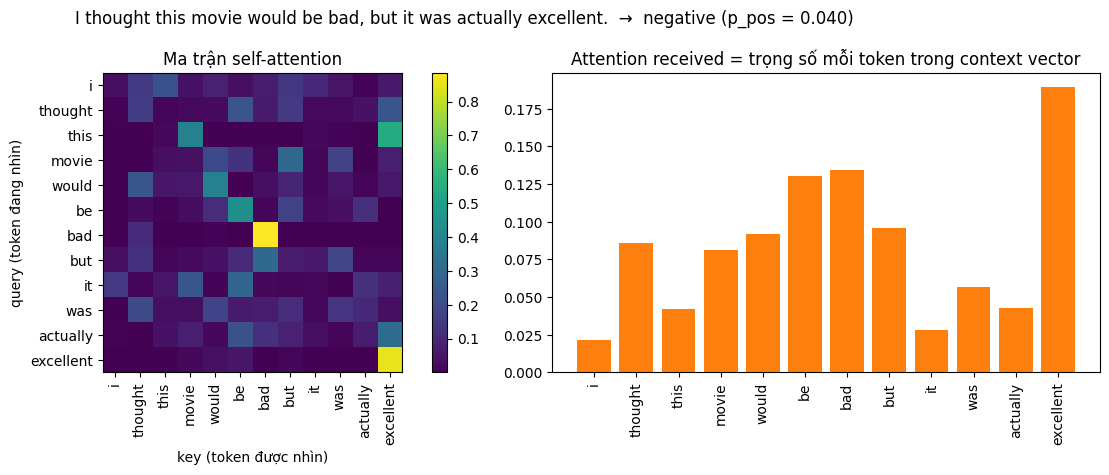

,Sentence,Expected,Prediction,P(neg),P(pos),Đúng?,Top-3 attended
0,I like this movie.,positive,negative,0.9989,0.0011,False,"[(like, 0.381), (movie, 0.363), (this, 0.218)]"
1,I do not like this movie.,negative,negative,0.9994,0.0006,True,"[(like, 0.473), (do, 0.232), (this, 0.123)]"
2,"I thought this movie would be bad, but it was actually excellent.",positive,negative,0.9597,0.0403,False,"[(excellent, 0.19), (bad, 0.134), (be, 0.13)]"


In [39]:
sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent.",
]
# Gán nhãn "kỳ vọng" để bạn tự đối chiếu
expected = ["positive", "negative", "positive"]

rows = []
for s, exp in zip(sentences, expected):
    r = analyze(s)
    top = np.argsort(-r["received"])[:3]
    rows.append({"Sentence": s, "Expected": exp, "Prediction": LABELS[r["pred"]],
                 "P(neg)": round(float(r["probs"][0]), 4), "P(pos)": round(float(r["probs"][1]), 4),
                 "Đúng?": LABELS[r["pred"]] == exp,
                 "Top-3 attended": [(r["toks"][i], round(float(r["received"][i]), 3)) for i in top]})
    plot_attention(r, title=s)

pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(rows))

### Phân tích mục 26
#### Câu 0 — "I like this movie."

- **Prediction:** `positive`
- **Xác suất:** P(negative) = `0.0011`, P(positive) = `0.9989`.
- Model rất tự tin với dự đoán `positive`.
- **Attention received cao nhất:**
  - `like`: `0.381`
  - `movie`: `0.363`
  - `this`: `0.218`
- Token `like` có attention received cao nhất và phù hợp với trực giác,
  vì đây là từ mang sentiment tích cực rõ ràng.
- Tuy nhiên, attention cao ở `like` **chưa chứng minh** rằng `like` là
  nguyên nhân trực tiếp khiến model dự đoán `positive`.

#### Câu 2 — "I thought this movie would be bad, but it was actually excellent."

- **Prediction:** `negative`
- **Expected:** `positive`
- **Xác suất:** P(negative) = `0.9597`, P(positive) = `0.0403`.
- Model rất tự tin nhưng **dự đoán sai**.
- **Attention received cao nhất:**
  - `excellent`: `0.190`
  - `bad`: `0.134`
  - `be`: `0.130`
- `excellent` có attention received cao nhất, phù hợp với trực giác vì
  đây là từ mang sentiment tích cực mạnh. Tuy nhiên, model vẫn dự đoán
  `negative`.
- Câu này có cấu trúc **contrast**:
  `would be bad, but ... excellent`.
  Model cần kết hợp thông tin giữa nhiều token ở các vị trí khác nhau
  để hiểu rằng `bad` thuộc về phần kỳ vọng ban đầu, còn `excellent`
  mô tả đánh giá thực tế.
- Ma trận self-attention T×T cho phép quan sát các tương tác giữa các
  token, chẳng hạn giữa `bad`, `but` và `excellent`. Tuy nhiên, chỉ
  dựa vào attention matrix **không đủ để kết luận** rằng model đã hoặc
  chưa hiểu đúng quan hệ contrast.

#### Kết luận

Model xử lý tốt câu ngắn có sentiment rõ ràng như
`I like this movie.` nhưng gặp khó khăn với câu có cấu trúc contrast
và phụ thuộc ngữ cảnh dài như
`bad, but ... excellent`.

Đáng chú ý, trong câu dự đoán sai, `excellent` vẫn có attention
received cao nhất. Điều này cho thấy **attention cao không đồng nghĩa
với việc token đó là nguyên nhân trực tiếp của prediction**. Đây là
điểm cần được kiểm tra sâu hơn trong **mục 27 — Error Analysis**.